In [26]:
import pandas as pd

import os 
os.getcwd()

os.listdir()

orders = pd.read_csv("olist_orders_dataset.csv")
orders.head()
orders.shape
orders.columns
orders.info()
orders.isnull().sum()

orders["order_status"].value_counts()
orders.dtypes
orders_clean = orders.copy()

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders_clean[col] = pd.to_datetime(orders_clean[col])

orders_clean.dtypes

orders_clean.info()


<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str 

In [27]:
orders_clean["order_id"].duplicated().sum()

orders_clean["customer_id"].duplicated().sum()
customers = pd.read_csv("olist_customers_dataset.csv")
customers.head()
customers.shape
customers.columns

customers["customer_unique_id"].nunique()
customers["customer_id"].nunique()

orders_customers = orders_clean.merge(
    customers,
    on="customer_id",
    how="left"
)

orders_customers.shape
orders_customers.head()
orders_customers["customer_unique_id"].nunique()
orders_customers["customer_unique_id"].value_counts().head()

customer_order_counts = orders_customers["customer_unique_id"].value_counts()

repeat_customers = (customer_order_counts > 1).sum()

total_customers = customer_order_counts.count()

repeat_customer_rate = (repeat_customers / total_customers) * 100

repeat_customers, total_customers, repeat_customer_rate

orders_customers["customer_state"].value_counts().head(10)
orders_customers["customer_state"].nunique()

order_items = pd.read_csv("olist_order_items_dataset.csv")
order_items.head()
order_items.shape
order_items.info()
total_revenue = order_items["price"].sum()
total_revenue
total_freight = order_items["freight_value"].sum()
total_freight

total_order_value = total_revenue + total_freight
total_order_value

total_orders = order_items["order_id"].nunique()
total_orders

aov = total_order_value / total_orders
aov

orders_items = orders_clean.merge(
    order_items,
    on="order_id",
    how="inner"
)
orders_items.shape

orders_items["purchase_month"] = orders_items["order_purchase_timestamp"].dt.to_period("M")

orders_items[["order_purchase_timestamp","purchase_month"]].head()

monthly_revenue = (
    orders_items.groupby("purchase_month")["price"]
    .sum()
    .reset_index()
)

monthly_revenue.head()

monthly_orders = (
    orders_items.groupby("purchase_month")["order_id"]
    .nunique()
    .reset_index(name="orders")
)

monthly_orders.head()

monthly_sales = monthly_revenue.merge(
    monthly_orders,
    on="purchase_month",
    how="left"
)


monthly_sales.head()

monthly_sales = monthly_sales.rename(
    columns={"price":"revenue"}
)

monthly_sales.head()

monthly_sales["aov"] = (
    monthly_sales["revenue"] / monthly_sales["orders"]
)

monthly_sales.head()

monthly_sales["revenue_growth_pct"] = (

monthly_sales["revenue"].pct_change() * 100
)

monthly_sales.head()

monthly_sales_2017 = monthly_sales[

monthly_sales["purchase_month"]>="2017-01"
].copy()
monthly_sales_2017.head()

monthly_sales_2017["revenue_growth_pct"] = (
    monthly_sales_2017["revenue"].pct_change() * 100
)

monthly_sales_2017.head()



<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 6.0 MB


,purchase_month,revenue,orders,aov,revenue_growth_pct
3,2017-01,120312.87,789,152.487795,NaN
4,2017-02,247303.02,1733,142.702262,105.549930
5,2017-03,374344.30,2641,141.743393,51.370695
6,2017-04,359927.23,2391,150.534182,-3.851286
7,2017-05,506071.14,3660,138.270803,40.603738


NameError: name 'plt' is not defined

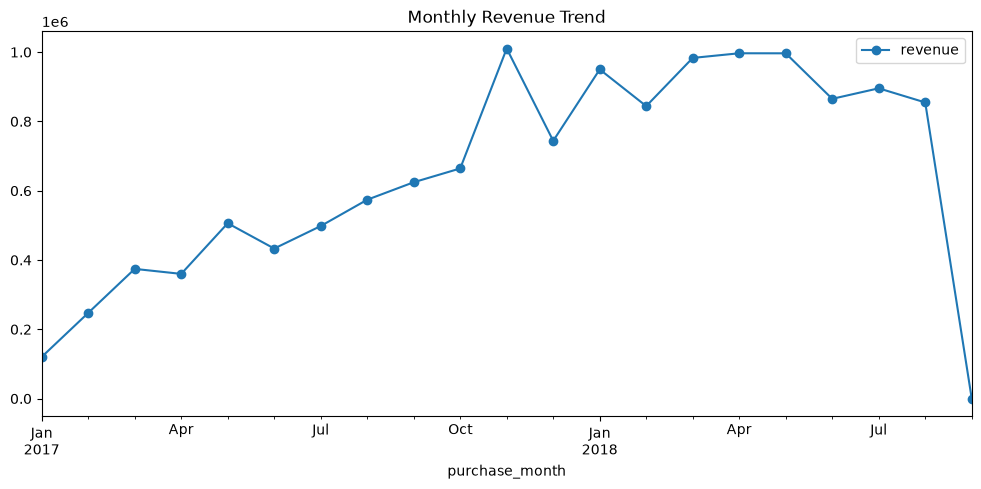

In [28]:
monthly_sales_2017.plot(
    x="purchase_month",
    y="revenue",
    kind="line",
    figsize=(12, 5),
    marker="o",
    title="Monthly Revenue Trend"
)

plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)
plt.show()

monthly_sales_2017.nsmallest(5,"revenue")

orders_items_geo = orders_items.merge(
    orders_customers[["order_id", "customer_state"]],
    on="order_id",
    how="left"


)

orders_items_geo.head()
orders_items_geo.groupby("customer_state")["price"].sum()

orders_items_geo.columns

state_revenue = (
    orders_items_geo.groupby("customer_state")["price"]
    .sum()
    .reset_index()
)

state_revenue


state_revenue = state_revenue.sort_values(
    "price",
    ascending=False
)

state_revenue.head(10)

state_orders = (
    orders_items_geo.groupby("customer_state")["order_id"]
    .nunique()
    .reset_index(name="orders")
)

state_orders = state_orders.sort_values(
    "orders",
    ascending=False
)

state_orders.head(10)
orders_


In [ ]:
orders_items_geo = orders_items.merge(
    orders_customers[["order_id", "customer_state"]],
    on="order_id",
    how="left"
)

orders_items_geo.shape

state_revenue = (
    orders_items_geo.groupby("customer_state")["price"]
    .sum()
    .reset_index()
)

state_revenue.head(10)

state_revenue = state_revenue.sort_values(
    "price",
    ascending=False
)

state_revenue.head(10)

state_orders = (
    orders_items_geo.groupby("customer_state")["order_id"]
    .nunique()
    .reset_index(name="orders")
)

state_orders = state_orders.sort_values(
    "orders",
    ascending=False
)

state_orders.head(10)

state_analysis = state_revenue.merge(
    state_orders,
    on="customer_state",
    how="inner"
)

state_analysis.head(10)

state_analysis["aov"] = (state_analysis["price"] / state_analysis["orders"])

state_analysis.head(10)

state_analysis = state_analysis.rename(columns={"price":"revenue"})

state_analysis.head(10)

state_analysis = state_analysis.sort_values(
    "aov",
    ascending=False
)

state_analysis.head(10)

total_revenue = state_analysis["revenue"].sum()

total_revenue

state_analysis["revenue_share_pct"] = (
    state_analysis["revenue"] / total_revenue * 100
    )

state_analysis.head(10)

state_analysis = state_analysis.sort_values("revenue",ascending=False)
state_analysis.head(10)

orders_items_geo.columns

products = pd.read_csv("olist_products_dataset.csv")


product_sales = orders_items_geo.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

product_sales.shape

product_sales[["product_id","product_category_name","price"]].head()

category_revenue = (product_sales.groupby("product_category_name")["price"]
.sum()
    .reset_index(name="revenue")
)

catogory_revenue = category_revenue.sort_values("revenue", ascending=False)

category_revenue.head(10)

category_revenue = category_revenue.sort_values("revenue",ascending=False)

category_revenue.head(10)

category_orders = (product_sales.groupby("product_category_name")["order_id"].nunique().reset_index(name="orders"))

category_orders = category_orders.sort_values("orders",ascending=False)
category_orders.head(10)

category_analysis = category_revenue.merge(category_orders,
on="product_category_name",how="inner")

category_analysis["aov"] = (category_analysis["revenue"] / category_analysis["orders"])

category_analysis.sort_values("aov",ascending=False).head(10)

orders_customers.columns

customer_orders = (orders_customers.groupby("customer_unique_id")["order_id"].nunique().reset_index(name="order_count"))

customer_orders.head()

customer_orders["order_count"].value_counts().sort_index().head(10)

repeat_customers = (customer_orders["order_count"] > 1).sum()
total_customers = len(customer_orders)

repeat_customer_rate = (
    repeat_customers / total_customers * 100
)

repeat_customer_rate



KeyError: 'order_count'

In [ ]:
product_sales.columns.tolist()

product_sales[["customer_unique_id", "order_count"]].head(10)

product_sales["customer_type"] = product_sales["order_count"].apply(
    lambda x: "Repeat" if x > 1 else "One-time"
)

product_sales[[
    "customer_unique_id",
    "order_count",
    "customer_type"
]].head(10)

customer_summary = (product_sales.groupby("customer_type")["customer_unique_id"].nunique().reset_index(name="customers"))

customer_summary

customer_type_revenue = (product_sales.groupby("customer_type")["price"].sum().reset_index(name="revenue"))

customer_type_revenue

customer_type_analysis = customer_summary.merge(customer_type_revenue,on="customer_type",how="inner")

customer_type_analysis["revenue_per_customer"] = (
    customer_type_analysis["revenue"] /
    customer_type_analysis["customers"]
)

customer_type_analysis

repeat_category = product_sales[
    product_sales["customer_type"] == "Repeat"
]

repeat_category.shape

repeat_category_orders = (
    repeat_category.groupby("product_category_name")["order_id"]
    .nunique()
    .reset_index(name="repeat_orders")
)

repeat_category_orders = repeat_category_orders.sort_values(
    "repeat_orders",
    ascending=False
)

repeat_category_orders.head(10)

category_total_orders = (
    product_sales.groupby("product_category_name")["order_id"]
    .nunique()
    .reset_index(name="total_orders")
)

category_repeat_analysis = category_total_orders.merge(
    repeat_category_orders,
    on="product_category_name",
    how="left"
)

category_repeat_analysis["repeat_order_rate"] = (
    category_repeat_analysis["repeat_orders"]
    / category_repeat_analysis["total_orders"]
    * 100
)

category_repeat_analysis.sort_values(
    "repeat_order_rate",
    ascending=False
).head(10)

category_repeat_analysis[category_repeat_analysis["total_orders"] >= 100].sort_values(
    "repeat_order_rate",ascending=False).head(10)

    


,product_category_name,total_orders,repeat_orders,repeat_order_rate
28,eletrodomesticos,764,138.0,18.062827
33,fashion_bolsas_e_acessorios,1864,230.0,12.339056
38,fashion_roupa_masculina,112,12.0,10.714286
10,bebidas,297,28.0,9.427609
13,cama_mesa_banho,9417,874.0,9.281087
54,moveis_decoracao,6449,597.0,9.257249
57,moveis_sala,422,37.0,8.767773
34,fashion_calcados,240,21.0,8.750000
19,climatizacao,253,22.0,8.695652
14,casa_conforto,397,32.0,8.060453


In [ ]:
orders_customers[
    [
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
].dtypes

orders_customers["delivery_delay_days"] = (
    orders_customers["order_delivered_customer_date"]
    - orders_customers["order_estimated_delivery_date"]
).dt.days

orders_customers[
    [
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "delivery_delay_days"
    ]
].head(10)

orders_customers["delivery_status"] = orders_customers["delivery_delay_days"].apply(
    lambda x: "late" if x > 0
    else "on-time" if x == 0
    else "early" if x < 0
    else "Not delivered"
)
orders_customers["delivery_status"].value_counts()

delivery_summary = (
    orders_customers.groupby("delivery_status")["order_id"]
    .nunique()
    .reset_index(name="orders")
)

delivery_summary

delivered_orders = delivery_summary[
    delivery_summary["delivery_status"] != "Not delivered"
]["orders"].sum()

late_orders = delivery_summary[
    delivery_summary["delivery_status"] == "late"
]["orders"].iloc[0]

late_delivery_rate = late_orders / delivered_orders * 100

late_delivery_rate

delivered_data = orders_customers[orders_customers["delivery_status"] != "Not delivered"]

delivered_data.shape

state_delivery = (delivered_data.groupby("customer_state")["order_id"].nunique().reset_index(name="delivered_orders"))

state_delivery.head(10)

state_late = (
    delivered_data[delivered_data["delivery_status"] == "late"]
    .groupby("customer_state")["order_id"]
    .nunique()
    .reset_index(name="late_orders")
)

state_late.head(10)

state_delivery_analysis = state_delivery.merge(state_late,
    on="customer_state",
    how="left"
)

state_delivery_analysis.head(10)

state_delivery_analysis["late_delivery_rate"] = (
    state_delivery_analysis["late_orders"] /
    state_delivery_analysis["delivered_orders"]
    *100
)

state_delivery_analysis = state_delivery_analysis.sort_values("late_delivery_rate",ascending=False)

state_delivery_analysis.head(10)

state_delivery_reliable = state_delivery_analysis[state_delivery_analysis["delivered_orders"] >=500]

state_delivery_reliable = state_delivery_analysis.sort_values(
    "late_delivery_rate",
     ascending=False)

state_delivery_reliable.head(10)

state_delivery_reliable = state_delivery_analysis[
    state_delivery_analysis["delivered_orders"] >= 500
]

state_delivery_reliable.sort_values(
    "late_delivery_rate",
    ascending=False
).head(10)

late_delivery_data = delivered_data[delivered_data["delivery_status"] == "late"]

average_late_days = late_delivery_data["delivery_delay_days"].mean()

average_late_days



KeyError: 'purchase_month'

In [175]:
orders_customers.columns.tolist()

orders_customers["order_purchase_timestamp"].dtype

orders_customers["purchase_month"] = (
    orders_customers["order_purchase_timestamp"]
    .dt.strftime("%Y-%m")
)

orders_customers[
    ["order_purchase_timestamp", "purchase_month"]
].head(10)

monthly_late = (
    orders_customers[
        orders_customers["delivery_status"] == "late"
    ]
    .groupby("purchase_month")["order_id"]
    .nunique()
    .reset_index(name="late_orders")
)

monthly_late = monthly_late.sort_values("purchase_month")

monthly_late.head(10)

delivered_data = orders_customers[
    orders_customers["delivery_status"] != "Not delivered"
]

monthly_delivered = (
    delivered_data
    .groupby("purchase_month")["order_id"]
    .nunique()
    .reset_index(name="delivered_orders")
)

monthly_delivery_analysis = monthly_delivered.merge(
    monthly_late,
    on="purchase_month",
    how="left"
)

monthly_delivery_analysis["late_delivery_rate"] = (
    monthly_delivery_analysis["late_orders"]
    / monthly_delivery_analysis["delivered_orders"]
    * 100
)

monthly_delivery_analysis.head(10)

monthly_delivery_analysis = monthly_delivery_analysis.sort_values(
    "purchase_month"
)

monthly_delivery_analysis

,purchase_month,delivered_orders,late_orders,late_delivery_rate
0,2016-09,1,1.0,100.000000
1,2016-10,270,2.0,0.740741
2,2016-12,1,NaN,NaN
3,2017-01,750,22.0,2.933333
4,2017-02,1653,49.0,2.964307
5,2017-03,2546,116.0,4.556167
6,2017-04,2303,151.0,6.556665
7,2017-05,3545,106.0,2.990127
8,2017-06,3135,95.0,3.030303
9,2017-07,3872,108.0,2.789256


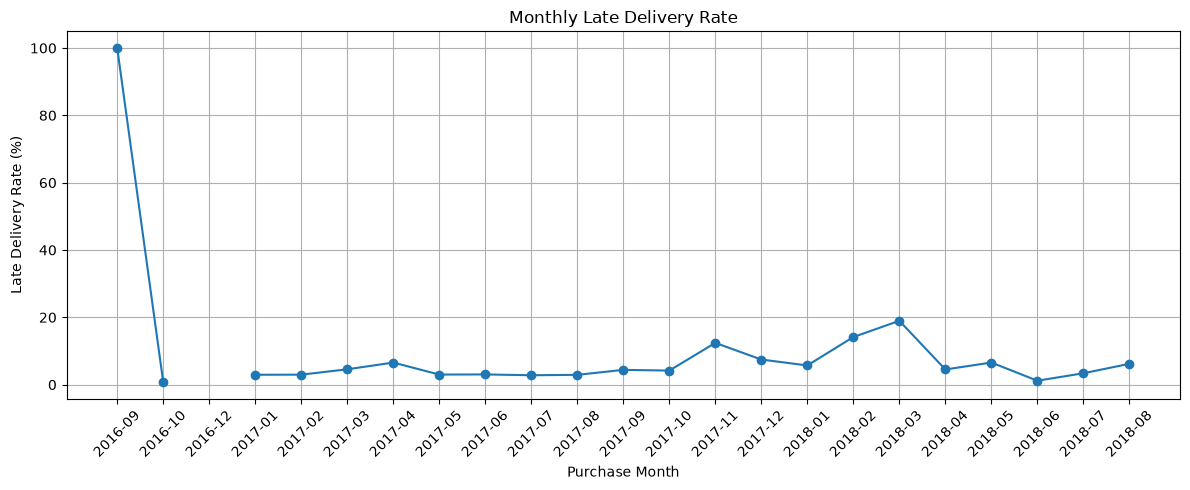

['order_id',
 'payment_sequential',
 'payment_type',
 'payment_installments',
 'payment_value']

In [180]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_delivery_analysis["purchase_month"],
    monthly_delivery_analysis["late_delivery_rate"],
    marker="o"
)

plt.title("Monthly Late Delivery Rate")
plt.xlabel("Purchase Month")
plt.ylabel("Late Delivery Rate (%)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

payments = pd.read_csv("olist_order_payments_dataset.csv")

payments.columns.tolist()

In [369]:
payments.columns.tolist()

payments.shape


payments["payment_type"].value_counts()

payment_revenue = (payments.groupby("payment_type")["payment_value"]
.sum()
.reset_index(name="revenue"))

payment_revenue = payment_revenue.sort_values("revenue",ascending=False)

payment_revenue

payment_aov = (payments.groupby("payment_type")["payment_value"]
.mean()
.reset_index(name="average_payment"))

payment_aov = payment_aov.sort_values("average_payment",ascending=False)

payment_aov

payments["payment_installments"].value_counts().sort_index()

installment_analysis = (
    payments.groupby("payment_installments")["payment_value"]
    .mean()
    .reset_index(name="average_payment")
)

installment_analysis.sort_values("payment_installments")

payment_count = (
    payments.groupby("payment_installments")["payment_value"]
    .count()
    .reset_index(name="payment_count")
)

average_payment = (
    payments.groupby("payment_installments")["payment_value"]
    .mean()
    .reset_index(name="average_payment")
)

installment_analysis = payment_count.merge(
    average_payment,
    on="payment_installments",
    how="left"
)

installment_analysis.sort_values(
    "payment_count",
    ascending=False
).head(10)


customer_payments = payments.merge(orders_customers[["order_id","customer_unique_id"]],
on="order_id",
how="left"

)

customer_payments[
    [
        "customer_unique_id",
        "order_id",
        "payment_type",
        "payment_installments",
        "payment_value"
    ]
].head(10)

customer_payment_summary = (customer_payments.groupby("customer_unique_id")["payment_value"]
.sum()
    .reset_index(name="total_paid")
)

customer_payment_summary.sort_values(
    "total_paid",
    ascending=False
).head(10)

customer_payment_methods = (customer_payments.groupby("customer_unique_id")["payment_type"]
.nunique()
.reset_index(name="payment_method_count"))

customer_payment_methods[
    customer_payment_methods["payment_method_count"] > 1].head(10)


customer_payment_methods_list = (customer_payments.groupby("customer_unique_id")["payment_type"]
.agg(lambda x: ",".join(x.unique()))
.reset_index(name="payment_methods")
)

customer_payment_methods_list.head(20)

customer_payment_profile = customer_payment_methods.merge(
    customer_payment_methods_list,
    on="customer_unique_id",
    how="left"
)

customer_payment_profile.head(10)

customer_payment_profile[
    customer_payment_profile["payment_method_count"] > 1
].head(10)

payment_method_combinations = (
    customer_payment_methods_list["payment_methods"]
    .value_counts()
)

payment_method_combinations.head(10)

customer_payment_methods_list["payment_methods"] = (
    customer_payment_methods_list["payment_methods"]
    .apply(lambda x: ",".join(sorted(x.split(","))))
)

payment_method_combinations = (
    customer_payment_methods_list["payment_methods"]
    .value_counts()
)

payment_method_combinations.head(10)

customer_payment_profile = customer_payment_profile.merge(
    customer_payment_summary,
    on="customer_unique_id",
    how="left"
)

customer_payment_profile.head(10)

payment_behavior_summary = (
    customer_payment_profile.groupby("payment_method_count")["total_paid"]
    .agg(["count","mean","sum",])
    .reset_index()
)

payment_behavior_summary

orders_customers.columns.tolist()

customer_orders.columns.tolist()

customer_orders["customer_type"] = customer_orders["order_count"].apply(
    lambda x: "repeat" if x > 1
else "one-time"
)

customer_value_profile = customer_orders.merge(
    customer_payment_profile,
    on="customer_unique_id",
    how="left"
)

customer_value_profile.head(10)

customer_type_value = (
    customer_value_profile
    .groupby("customer_type")["total_paid"]
    .agg(["count","mean","sum"])
    .reset_index()
)
customer_type_value

repeat_customers = customer_value_profile[customer_value_profile["customer_type"] == "repeat"]

repeat_customers.shape

top_repeat_customers = repeat_customers.sort_values("total_paid",ascending=False).head(10)
top_repeat_customers

repeat_order_value = (repeat_customers.groupby("order_count")["total_paid"]
.agg(["count","mean","sum"])
.reset_index()
)
repeat_order_value

order_items.columns.tolist()
products.columns.tolist()

order_items_with_category = order_items.merge(
    products[["product_id","product_category_name"]],
    on="product_id",
    how="left"
)

order_items_with_category.head()

repeat_order_items = order_items_with_category.merge(
    orders_customers[["order_id","customer_unique_id"]],
    on="order_id",
    how="left"
)
repeat_order_items.head()

repeat_customers_ids = customer_orders[
    customer_orders["customer_type"] == "repeat"
]["customer_unique_id"]

repeat_customers_ids.head()

repeat_customer_ids = customer_orders.loc[
    customer_orders["customer_type"] == "repeat",
    "customer_unique_id"
]


repeat_customer_ids = customer_orders.loc[
    customer_orders["customer_type"] == "repeat",
    "customer_unique_id"
]

repeat_customer_ids.head()

repeat_customers = customer_orders[
    customer_orders["customer_unique_id"].isin(repeat_customer_ids)].copy()
repeat_customers.head()

repeat_customers.columns.tolist()
[name for name in globals() if isinstance(globals()[name], pd.DataFrame)]

repeat_order_items.columns.tolist()

repeat_category_analysis = (
    repeat_order_items
    .groupby("product_category_name")["price"]
    .agg(["count", "sum", "mean"])
    .reset_index()
    .sort_values("sum", ascending=False)
)

repeat_category_analysis.head(10)

repeat_category_customers = (
    repeat_order_items
    .groupby("product_category_name")["customer_unique_id"]
    .nunique()
    .reset_index(name="unique_repeat_customers")
    .sort_values("unique_repeat_customers", ascending=False)
)

repeat_category_customers.head(10)

category_value = (
    repeat_category_analysis[
        ["product_category_name", "sum"]
    ]
    .merge(
        repeat_category_customers,
        on="product_category_name"
    )
)

category_value["revenue_per_repeat_customer"] = (
    category_value["sum"] /
    category_value["unique_repeat_customers"]
)

category_value = category_value.sort_values(
    "revenue_per_repeat_customer",
    ascending=False
)

category_value.head(10)

strong_repeat_categories = category_value[
    category_value["unique_repeat_customers"] >= 500
].sort_values(
    "revenue_per_repeat_customer",
    ascending=False
)

strong_repeat_categories.head(10)

repeat_customers.columns.tolist()

customer_value = (
    repeat_order_items
    .groupby("customer_unique_id")
    .agg(
        order_count=("order_id", "nunique"),
        total_spending=("price", "sum")
    )
    .reset_index()
)

customer_value.head()

repeat_order_items_filtered = repeat_order_items[
    repeat_order_items["customer_unique_id"].isin(repeat_customer_ids)].copy()

repeat_order_items_filtered["customer_unique_id"].nunique()

customer_value = (
    repeat_order_items_filtered
    .groupby("customer_unique_id")
    .agg(
        order_count=("order_id", "nunique"),
        total_spending=("price", "sum")
    )
    .reset_index()
)

customer_value.head()

customer_value["order_count"].value_counts().sort_index()

check_repeat_orders = (
    repeat_customers[["customer_unique_id", "order_count"]]
    .merge(
        customer_value[["customer_unique_id", "order_count"]],
        on="customer_unique_id",
        suffixes=("_original", "_items")
    )
)

check_repeat_orders.head(10)

customer_value = (
    repeat_order_items_filtered
    .groupby("customer_unique_id")
    .agg(
        total_spending=("price", "sum")
    )
    .reset_index()
    .merge(
        repeat_customers[["customer_unique_id", "order_count"]],
        on="customer_unique_id",
        how="left"
    )
)

customer_value = customer_value[
    ["customer_unique_id", "order_count", "total_spending"]
]

customer_value.head()

customer_value["total_spending"].describe()

high_value_customers = customer_value[
    customer_value["total_spending"] > customer_value["total_spending"].quantile(0.75)].copy()
high_value_customers.head()

len(high_value_customers)


customer_value.columns

customer_value["value_segment"] = customer_value["total_spending"].apply(
    lambda x: "High Value"
    if x > customer_value["total_spending"].quantile(0.75)
    else "Other Repeat")

customer_value.groupby("value_segment")["order_count"].agg(
    ["count", "mean", "median"]
).reset_index()

customer_value.groupby("value_segment")["total_spending"].agg(
    ["count", "mean", "median", "sum"]
).reset_index()


sellers = pd.read_csv("olist_sellers_dataset.csv")

sellers.shape

sellers.columns.tolist()

seller_sales = order_items.merge(sellers,
on="seller_id",
how="left")

seller_sales.columns.tolist()

top_sellers_revenue = (
    seller_sales
    .groupby("seller_id")["price"]
    .sum()
    .sort_values(ascending=False)
    .reset_index(name="total_revenue")
)

top_sellers_revenue.head(10)

top_sellers_orders = (
    seller_sales.groupby("seller_id")["order_id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="order_count")
)

top_sellers_orders.head(10)

seller_performance = (
    seller_sales
    .groupby("seller_id")
    .agg(
        total_revenue=("price", "sum"),
        order_count=("order_id", "nunique")
    )
    .reset_index()
)

seller_performance["avg_order_value"] = (
    seller_performance["total_revenue"] /
    seller_performance["order_count"]
)

seller_performance.sort_values(
    "avg_order_value",
    ascending=False
).head(10)


seller_performance_10plus = seller_performance[
    seller_performance["order_count"] >= 10
]

seller_performance_10plus.sort_values(
    "avg_order_value",
    ascending=False
).head(10)

seller_state_summary = (
    sellers
    .groupby("seller_state")
    .size()
    .sort_values(ascending=False)
    .reset_index(name="seller_count")
)

seller_state_summary.head(10)

reviews = pd.read_csv("olist_order_reviews_dataset.csv")

reviews.shape

seller_reviews = seller_sales.merge(
    reviews[["order_id", "review_score"]],
    on="order_id",
    how="left"
)

seller_reviews.columns.tolist()

seller_review_performance = (
    seller_reviews.groupby("seller_id")["review_score"]
    .mean()
    .sort_values(ascending=False)
    .reset_index(name = "avg_review_score")
)
seller_review_performance.head(10)

seller_review_summary = (
    seller_reviews
    .groupby("seller_id")
    .agg(
        avg_review_score=("review_score", "mean"),
        review_count=("review_score", "count")
    )
    .reset_index()
)

seller_review_summary_10plus = seller_review_summary[
    seller_review_summary["review_count"] >= 10
]

seller_review_summary_10plus.sort_values(
    "avg_review_score",
    ascending=False
).head(10)

seller_final_performance = seller_performance.merge(
    seller_review_summary,
    on="seller_id",
    how="left"
)

seller_final_performance.head()

total_orders = orders["order_id"].nunique()

total_customers = customers["customer_unique_id"].nunique()

total_revenue = order_items["price"].sum()

average_order_value = total_revenue / total_orders

print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Revenue:", round(total_revenue, 2))
print("Average Order Value:", round(average_order_value, 2))

repeat_customers_count = (
    customer_orders["customer_type"] == "repeat"
).sum()

one_time_customers_count = (
    customer_orders["customer_type"] == "one-time"
).sum()

repeat_customer_percentage = (
    repeat_customers_count / len(customer_orders)
) * 100

print("Repeat Customers:", repeat_customers_count)
print("One-time Customers:", one_time_customers_count)
print("Repeat Customer %:", round(repeat_customer_percentage, 2))


payment_summary = (
    payments
    .groupby("payment_type")["payment_value"]
    .sum()
    .sort_values(ascending=False)
    .reset_index(name="total_payment_value")
)

payment_summary

Total Orders: 99441
Total Customers: 96096
Total Revenue: 13591643.7
Average Order Value: 136.68
Repeat Customers: 2997
One-time Customers: 93099
Repeat Customer %: 3.12


,payment_type,total_payment_value
0,credit_card,12542084.19
1,boleto,2869361.27
2,voucher,379436.87
3,debit_card,217989.79
4,not_defined,0.00
